In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv("../../IMDB Dataset.csv")


df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [7]:
print("Dataset shape:", df.shape)
print("Total reviews:", len(df))
print("Column names:", df.columns.tolist())

Dataset shape: (50000, 2)
Total reviews: 50000
Column names: ['review', 'sentiment']


In [8]:
print(df["sentiment"].value_counts())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [9]:
print("Sentiment percentages:")
print(df["sentiment"].value_counts(normalize=True) * 100)

Sentiment percentages:
sentiment
positive    50.0
negative    50.0
Name: proportion, dtype: float64


In [10]:
majority_baseline = df["sentiment"].value_counts(normalize=True).max() * 100

print("Majority baseline accuracy:", majority_baseline, "%")

Majority baseline accuracy: 50.0 %


In [11]:
df["word_count"] = df["review"].apply(lambda x: len(x.split()))

print(df[["review", "word_count"]].head())

                                              review  word_count
0  One of the other reviewers has mentioned that ...         307
1  A wonderful little production. <br /><br />The...         162
2  I thought this was a wonderful way to spend ti...         166
3  Basically there's a family where a little boy ...         138
4  Petter Mattei's "Love in the Time of Money" is...         230


In [12]:
print("Mean:", df["word_count"].mean())

print("Median:", df["word_count"].median())

print("Mode:", df["word_count"].mode().tolist())

Mean: 231.15694
Median: 173.0
Mode: [127]


In [13]:
print("Variance:", df["word_count"].var())
print("Standard Deviation:", df["word_count"].std())

Variance: 29358.765405144506
Standard Deviation: 171.34399728366472


In [14]:
print(df.groupby("sentiment")["word_count"].mean())

sentiment
negative    229.46456
positive    232.84932
Name: word_count, dtype: float64


In [15]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 418


In [16]:
print("Skewness:", df["word_count"].skew())

Skewness: 2.1683033583491094


In [17]:
print(df.groupby("sentiment")["word_count"].skew())

sentiment
negative    2.083424
positive    2.225370
Name: word_count, dtype: float64


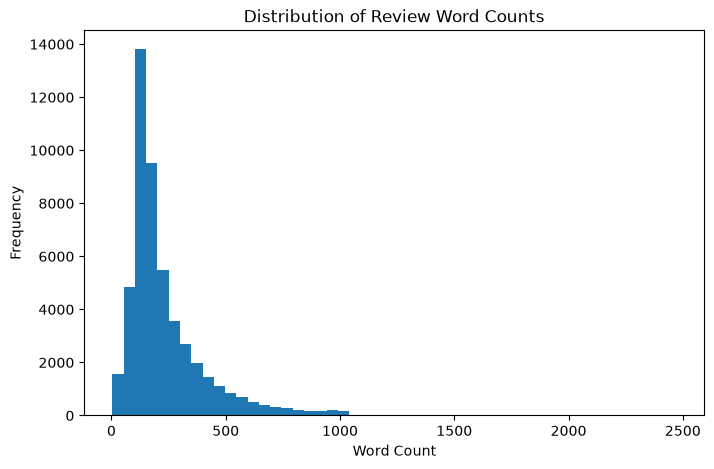

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["word_count"], bins=50)
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.title("Distribution of Review Word Counts")
plt.show()

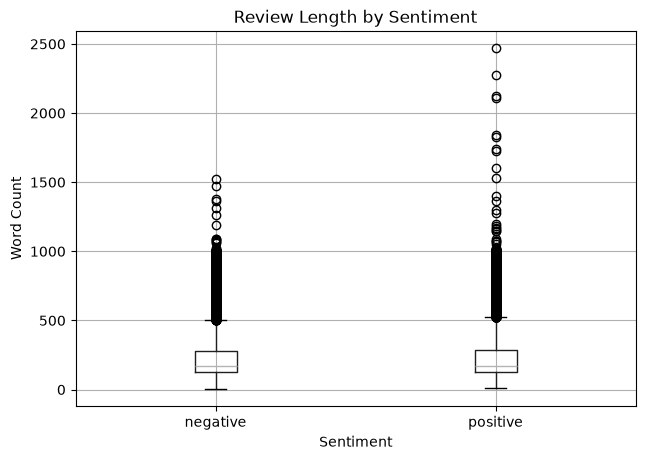

In [19]:
df.boxplot(column="word_count", by="sentiment", figsize=(7, 5))
plt.title("Review Length by Sentiment")
plt.suptitle("")
plt.xlabel("Sentiment")
plt.ylabel("Word Count")
plt.show()

In [2]:
import os
print(os.getcwd())

c:\Users\angel\OneDrive\Desktop\IMDB_Sentiment_Classifier\dataset\notebooks


In [20]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\angel\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\angel\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\angel\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\angel\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\angel\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\angel\AppData\Roaming\nltk_data...


True

In [4]:
import os

print("Current folder:", os.getcwd())
print("Files here:", os.listdir())
print("Parent folder:", os.listdir(".."))

Current folder: c:\Users\angel\OneDrive\Desktop\IMDB_Sentiment_Classifier\dataset\notebooks
Files here: ['imdb_analysis.ipynb', 'src']
Parent folder: ['notebooks']


In [21]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from bs4 import BeautifulSoup
import re

In [22]:
stop_words = set(stopwords.words("english"))

print("Total stopwords:", len(stop_words))

Total stopwords: 198


In [23]:
negation_words = {"not", "no", "never", "nor", "neither", "cannot"}

stop_words = stop_words - negation_words

print("Stopwords after preserving negations:", len(stop_words))

Stopwords after preserving negations: 195


In [24]:
lemmatizer = WordNetLemmatizer()

print("Lemmatizer initialized successfully!")

Lemmatizer initialized successfully!


In [5]:
import os
print(os.listdir("../.."))

['.venv', 'dataset', 'IMDB Dataset.csv']


In [25]:
def clean_review(text):
    # Remove HTML tags
    text = BeautifulSoup(text, "html.parser").get_text()

    # Convert to lowercase
    text = text.lower()

    # Tokenize the text
    words = word_tokenize(text)

    # Remove stopwords and non-alphabetic tokens
    words = [
        word for word in words
        if word.isalpha() and word not in stop_words
    ]

    # Apply lemmatization
    words = [lemmatizer.lemmatize(word) for word in words]

    # Join words into a sentence
    return " ".join(words)

In [26]:
sample_review = df["review"][0]

print("ORIGINAL REVIEW:\n")
print(sample_review[:500])

print("\nCLEANED REVIEW:\n")
print(clean_review(sample_review)[:500])

ORIGINAL REVIEW:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ

CLEANED REVIEW:

one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy not high agenda em city home many aryan muslim gangsta

In [27]:
sample = df["review"][0]

html_removed = BeautifulSoup(sample, "html.parser").get_text()

print(html_removed[:500])

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.It is called OZ as that is the nickname


In [28]:
tokens = word_tokenize(html_removed)

print(tokens[:50])

['One', 'of', 'the', 'other', 'reviewers', 'has', 'mentioned', 'that', 'after', 'watching', 'just', '1', 'Oz', 'episode', 'you', "'ll", 'be', 'hooked', '.', 'They', 'are', 'right', ',', 'as', 'this', 'is', 'exactly', 'what', 'happened', 'with', 'me.The', 'first', 'thing', 'that', 'struck', 'me', 'about', 'Oz', 'was', 'its', 'brutality', 'and', 'unflinching', 'scenes', 'of', 'violence', ',', 'which', 'set', 'in']


In [29]:

tokens_lower = [word.lower() for word in tokens]

filtered_words = [
    word for word in tokens_lower
    if word.isalpha() and word not in stop_words
]

print(filtered_words[:50])

['one', 'reviewers', 'mentioned', 'watching', 'oz', 'episode', 'hooked', 'right', 'exactly', 'happened', 'first', 'thing', 'struck', 'oz', 'brutality', 'unflinching', 'scenes', 'violence', 'set', 'right', 'word', 'go', 'trust', 'not', 'show', 'faint', 'hearted', 'timid', 'show', 'pulls', 'no', 'punches', 'regards', 'drugs', 'sex', 'violence', 'hardcore', 'classic', 'use', 'called', 'oz', 'nickname', 'given', 'oswald', 'maximum', 'security', 'state', 'penitentary', 'focuses', 'mainly']


In [30]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

stemmed_words = [stemmer.stem(word) for word in filtered_words]

print(stemmed_words[:50])

['one', 'review', 'mention', 'watch', 'oz', 'episod', 'hook', 'right', 'exactli', 'happen', 'first', 'thing', 'struck', 'oz', 'brutal', 'unflinch', 'scene', 'violenc', 'set', 'right', 'word', 'go', 'trust', 'not', 'show', 'faint', 'heart', 'timid', 'show', 'pull', 'no', 'punch', 'regard', 'drug', 'sex', 'violenc', 'hardcor', 'classic', 'use', 'call', 'oz', 'nicknam', 'given', 'oswald', 'maximum', 'secur', 'state', 'penitentari', 'focus', 'mainli']


In [31]:
lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in filtered_words
]

print(lemmatized_words[:50])

['one', 'reviewer', 'mentioned', 'watching', 'oz', 'episode', 'hooked', 'right', 'exactly', 'happened', 'first', 'thing', 'struck', 'oz', 'brutality', 'unflinching', 'scene', 'violence', 'set', 'right', 'word', 'go', 'trust', 'not', 'show', 'faint', 'hearted', 'timid', 'show', 'pull', 'no', 'punch', 'regard', 'drug', 'sex', 'violence', 'hardcore', 'classic', 'use', 'called', 'oz', 'nickname', 'given', 'oswald', 'maximum', 'security', 'state', 'penitentary', 'focus', 'mainly']


In [32]:
import time

start_time = time.time()

for review in df["review"][:1000]:
    clean_review(review)

end_time = time.time()

print("Time taken for 1000 reviews:", round(end_time - start_time, 2), "seconds")

Time taken for 1000 reviews: 2.91 seconds


In [33]:
df["cleaned_review"] = df["review"].apply(clean_review)

empty_reviews = (df["cleaned_review"] == "").sum()

print("Empty reviews:", empty_reviews)

Empty reviews: 0


In [34]:
from sklearn.model_selection import train_test_split

X = df["cleaned_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40000
Testing samples: 10000


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.8,
    max_features=50000,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

Training matrix: (40000, 50000)
Testing matrix: (10000, 50000)


In [36]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB(alpha=0.5)

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [37]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print("First 10 predictions:")
print(y_pred[:10])

Predictions completed!
First 10 predictions:
['negative' 'positive' 'positive' 'negative' 'negative' 'negative'
 'negative' 'negative' 'negative' 'negative']


In [38]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("Baseline Accuracy: 50.0 %")

Model Accuracy: 88.35 %
Baseline Accuracy: 50.0 %


In [39]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.89      0.87      0.88      5000
    positive       0.88      0.89      0.88      5000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



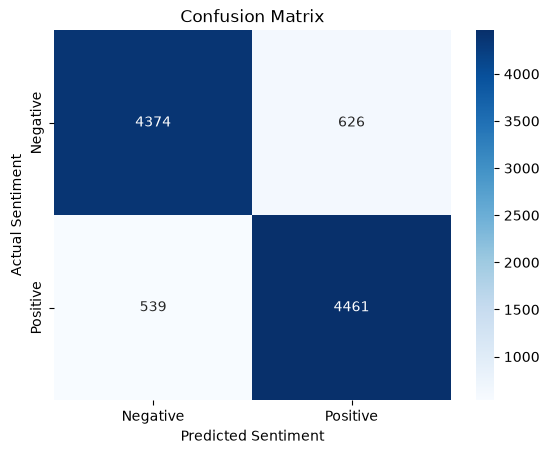

[[4374  626]
 [ 539 4461]]


In [40]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=["negative", "positive"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")
plt.show()

print(cm)

In [41]:
feature_names = tfidf.get_feature_names_out()
log_prob = model.feature_log_prob_

positive_indices = log_prob[1].argsort()[-20:][::-1]
negative_indices = log_prob[0].argsort()[-20:][::-1]

print("TOP 20 POSITIVE WORDS:")
print(feature_names[positive_indices])

print("\nTOP 20 NEGATIVE WORDS:")
print(feature_names[negative_indices])

TOP 20 POSITIVE WORDS:
['film' 'movie' 'one' 'not' 'great' 'like' 'good' 'time' 'story' 'see'
 'character' 'well' 'love' 'also' 'really' 'best' 'get' 'make' 'would'
 'life']

TOP 20 NEGATIVE WORDS:
['movie' 'film' 'not' 'one' 'like' 'bad' 'no' 'even' 'would' 'good' 'time'
 'could' 'character' 'really' 'get' 'make' 'scene' 'see' 'acting' 'plot']


In [42]:
bigram_vectorizer = TfidfVectorizer(
    ngram_range=(2, 2),
    min_df=5,
    max_features=50000
)

X_bigram = bigram_vectorizer.fit_transform(X_train)

bigram_model = MultinomialNB(alpha=0.5)
bigram_model.fit(X_bigram, y_train)

bigram_names = bigram_vectorizer.get_feature_names_out()

for sentiment_index, sentiment in enumerate(bigram_model.classes_):
    indices = bigram_model.feature_log_prob_[sentiment_index].argsort()[-10:][::-1]
    print("\nTop bigrams for", sentiment)
    print(bigram_names[indices])


Top bigrams for negative
['look like' 'waste time' 'ever seen' 'movie ever' 'worst movie'
 'special effect' 'not even' 'bad movie' 'movie not' 'one worst']

Top bigrams for positive
['one best' 'first time' 'even though' 'ever seen' 'film not'
 'great movie' 'movie not' 'new york' 'see movie' 'good movie']
